# 🌱 Plant Disease Prediction

## End-to-End Deep Learning Capstone Project

### Objective

Build a deep learning system that can identify plant diseases
from leaf images.

### Dataset

PlantVillage Color Dataset

- 38 classes
- 54,305 images
- Image size: 256 × 256
- RGB color images

### Project Pipeline

1. Dataset Exploration
2. Exploratory Data Analysis
3. Data Preprocessing
4. Data Splitting
5. Data Augmentation
6. Model Development
7. Model Training
8. Model Evaluation
9. Model Comparison
10. Final Prediction
11. Model Saving
12. Deployment

In [1]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("Environment loaded successfully!")
print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Environment loaded successfully!
Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 3.0.5


In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd().parent

# Dataset paths
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "plantvillage dataset"
COLOR_DATASET = DATA_ROOT / "color"

print("Project Root:")
print(PROJECT_ROOT)

print("\nDataset Path:")
print(COLOR_DATASET)

print("\nDataset exists:", COLOR_DATASET.exists())

Project Root:
c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project

Dataset Path:
c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\data\raw\plantvillage dataset\color

Dataset exists: True


Discover Classes & Count Images

In [3]:
# ============================================================
# DATASET DISCOVERY
# ============================================================

# Get all class folders
class_names = sorted([
    folder.name
    for folder in COLOR_DATASET.iterdir()
    if folder.is_dir()
])

print("Number of classes:", len(class_names))

print("\nClasses:")
for index, class_name in enumerate(class_names):
    print(f"{index:2d}. {class_name}")

Number of classes: 38

Classes:
 0. Apple___Apple_scab
 1. Apple___Black_rot
 2. Apple___Cedar_apple_rust
 3. Apple___healthy
 4. Blueberry___healthy
 5. Cherry_(including_sour)___Powdery_mildew
 6. Cherry_(including_sour)___healthy
 7. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 8. Corn_(maize)___Common_rust_
 9. Corn_(maize)___Northern_Leaf_Blight
10. Corn_(maize)___healthy
11. Grape___Black_rot
12. Grape___Esca_(Black_Measles)
13. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14. Grape___healthy
15. Orange___Haunglongbing_(Citrus_greening)
16. Peach___Bacterial_spot
17. Peach___healthy
18. Pepper,_bell___Bacterial_spot
19. Pepper,_bell___healthy
20. Potato___Early_blight
21. Potato___Late_blight
22. Potato___healthy
23. Raspberry___healthy
24. Soybean___healthy
25. Squash___Powdery_mildew
26. Strawberry___Leaf_scorch
27. Strawberry___healthy
28. Tomato___Bacterial_spot
29. Tomato___Early_blight
30. Tomato___Late_blight
31. Tomato___Leaf_Mold
32. Tomato___Septoria_leaf_spot
33. 

Count Images

In [4]:
# ============================================================
# IMAGE COUNT PER CLASS
# ============================================================

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = {}

for class_name in class_names:
    class_folder = COLOR_DATASET / class_name

    count = sum(
        1
        for file in class_folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

    class_counts[class_name] = count

class_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

print("Total images:", class_distribution["Image_Count"].sum())
print("Total classes:", len(class_distribution))

class_distribution

Total images: 54305
Total classes: 38


,Class,Image_Count
0,Apple___Apple_scab,630
1,Apple___Black_rot,621
2,Apple___Cedar_apple_rust,275
3,Apple___healthy,1645
4,Blueberry___healthy,1502
5,Cherry_(including_sour)___Powdery_mildew,1052
6,Cherry_(including_sour)___healthy,854
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,513
8,Corn_(maize)___Common_rust_,1192
9,Corn_(maize)___Northern_Leaf_Blight,985


EDA — Class Distribution

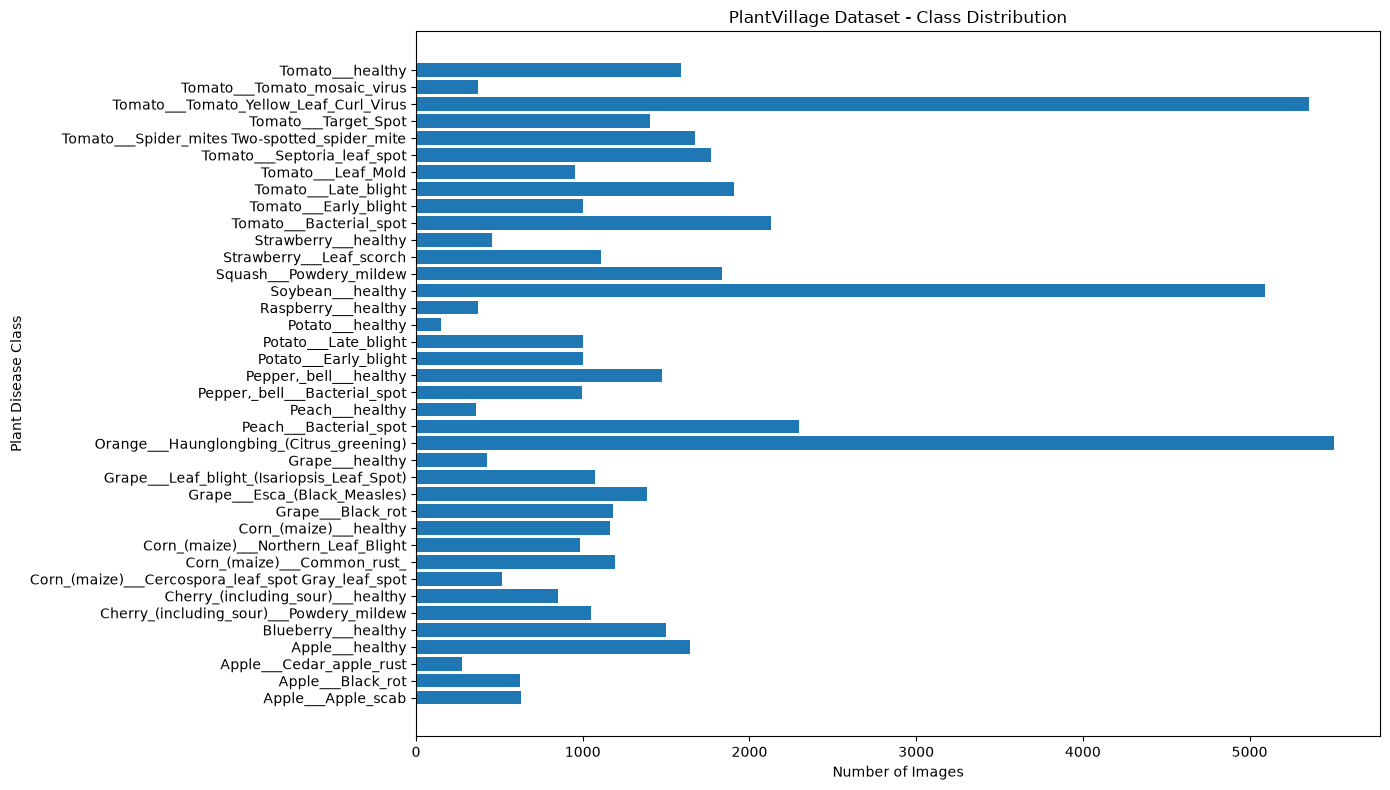

In [5]:
# ============================================================
# CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(14, 8))

plt.barh(
    class_distribution["Class"],
    class_distribution["Image_Count"]
)

plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Class")
plt.title("PlantVillage Dataset - Class Distribution")

plt.tight_layout()
plt.show()

Visualize Sample Images

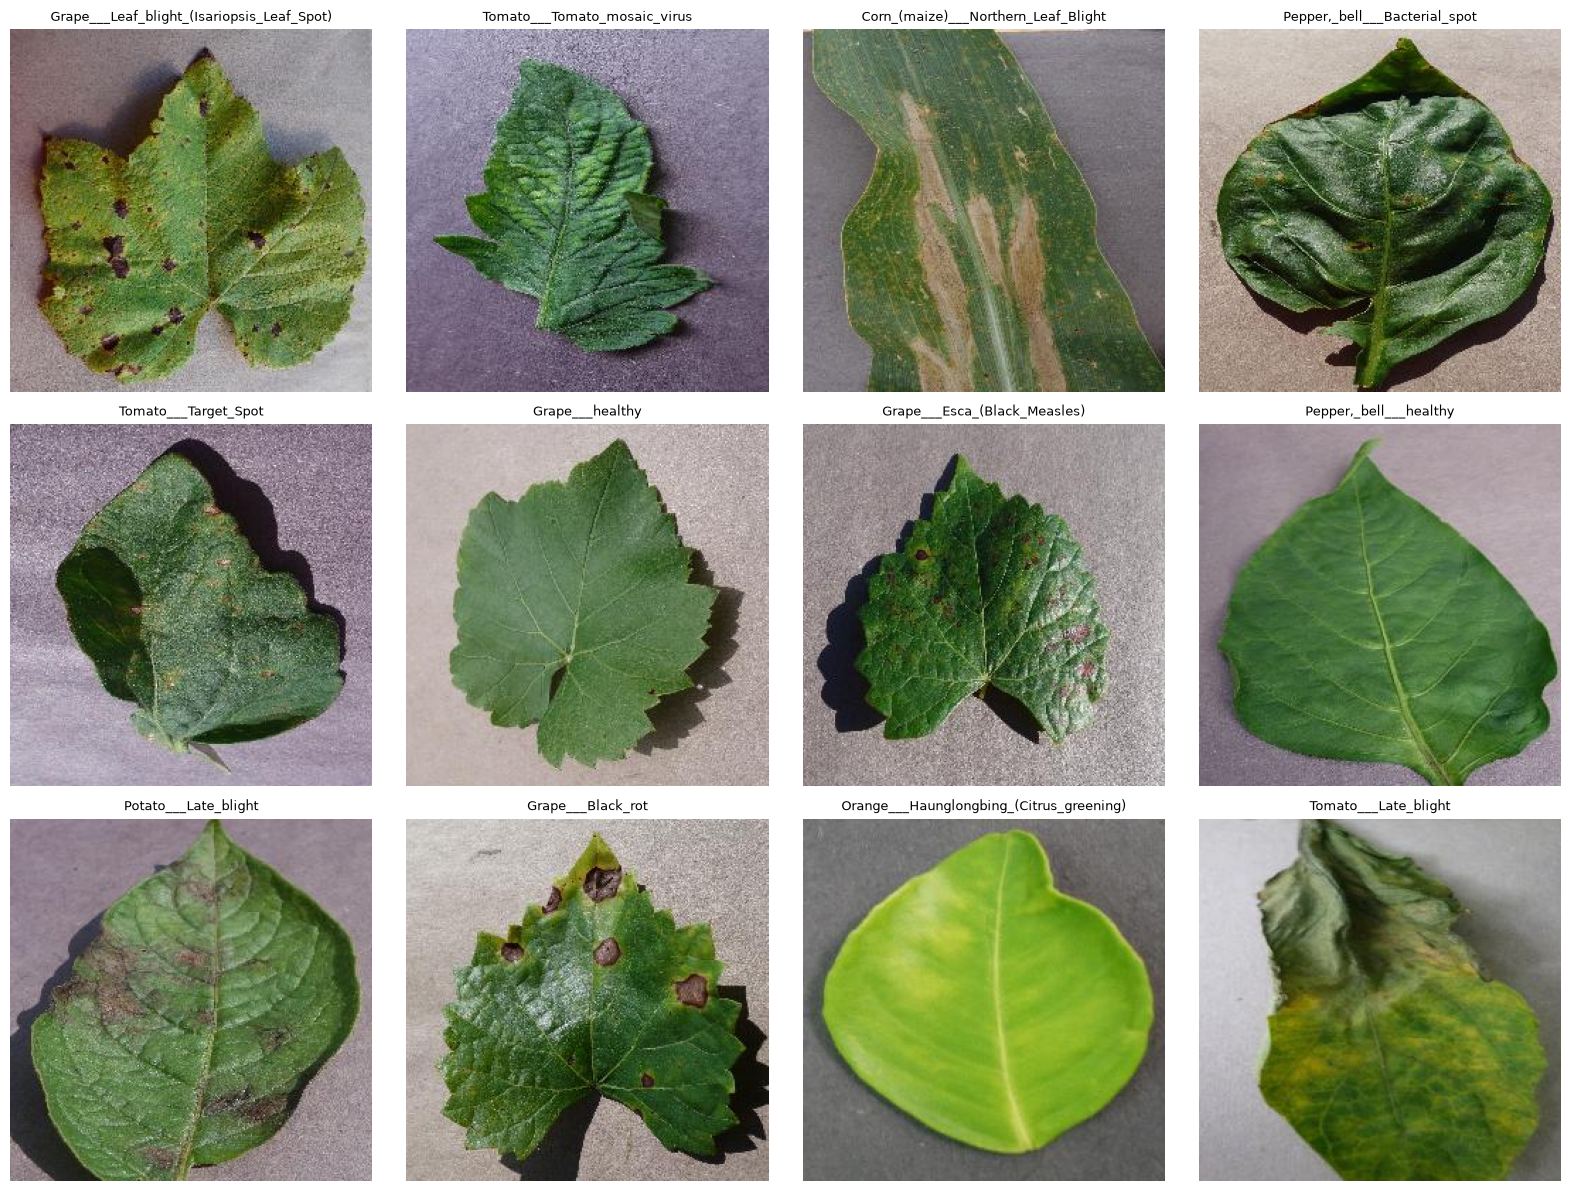

In [6]:
# ============================================================
# SAMPLE IMAGES FROM DIFFERENT CLASSES
# ============================================================

num_samples = 12

sample_classes = random.sample(class_names, num_samples)

plt.figure(figsize=(16, 12))

for i, class_name in enumerate(sample_classes):
    class_folder = COLOR_DATASET / class_name

    image_files = [
        file for file in class_folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    image_path = random.choice(image_files)

    image = Image.open(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

Image Dimensions & Format

In [7]:
# ============================================================
# IMAGE DIMENSION & FORMAT CHECK
# ============================================================

sample_info = []

for class_name in class_names:
    class_folder = COLOR_DATASET / class_name

    image_files = [
        file for file in class_folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    # Check a few images from each class
    for image_path in image_files[:5]:
        try:
            with Image.open(image_path) as img:
                sample_info.append({
                    "Class": class_name,
                    "Width": img.width,
                    "Height": img.height,
                    "Mode": img.mode,
                    "Format": img.format
                })
        except Exception:
            pass

image_info = pd.DataFrame(sample_info)

print("Images checked:", len(image_info))

print("\nImage dimensions:")
print(
    image_info[["Width", "Height"]]
    .drop_duplicates()
    .to_string(index=False)
)

print("\nImage modes:")
print(image_info["Mode"].value_counts())

print("\nImage formats:")
print(image_info["Format"].value_counts())

Images checked: 190

Image dimensions:
 Width  Height
   256     256

Image modes:
Mode
RGB    190
Name: count, dtype: int64

Image formats:
Format
JPEG    190
Name: count, dtype: int64


Create Dataset Index

In [8]:
# ============================================================
# CREATE DATASET INDEX
# ============================================================

records = []

for label, class_name in enumerate(class_names):

    class_folder = COLOR_DATASET / class_name

    for image_path in class_folder.iterdir():

        if (
            image_path.is_file()
            and image_path.suffix.lower() in image_extensions
        ):
            records.append({
                "image_path": str(image_path),
                "class_name": class_name,
                "label": label
            })

dataset_df = pd.DataFrame(records)

print("Total images:", len(dataset_df))
print("Total classes:", dataset_df["class_name"].nunique())

dataset_df.head()

Total images: 54305
Total classes: 38


,image_path,class_name,label
0,c:\Users\deept\OneDrive\Desktop\Plant_Disease ...,Apple___Apple_scab,0
1,c:\Users\deept\OneDrive\Desktop\Plant_Disease ...,Apple___Apple_scab,0
2,c:\Users\deept\OneDrive\Desktop\Plant_Disease ...,Apple___Apple_scab,0
3,c:\Users\deept\OneDrive\Desktop\Plant_Disease ...,Apple___Apple_scab,0
4,c:\Users\deept\OneDrive\Desktop\Plant_Disease ...,Apple___Apple_scab,0


Train / Validation / Test Split

In [9]:
# ============================================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.30,
    stratify=dataset_df["label"],
    random_state=42
)

# Second split: divide the 30% temporary data equally
# into 15% validation and 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Test images       :", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Training images   : 38013
Validation images : 8146
Test images       : 8146

Total: 54305


Verify Class Distribution Across Splits

In [10]:
# ============================================================
# VERIFY CLASS DISTRIBUTION ACROSS SPLITS
# ============================================================

split_summary = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).fillna(0).astype(int)

split_summary["Total"] = (
    split_summary["Train"]
    + split_summary["Validation"]
    + split_summary["Test"]
)

print("Number of classes in each split:")
print("Train      :", train_df["class_name"].nunique())
print("Validation :", val_df["class_name"].nunique())
print("Test       :", test_df["class_name"].nunique())

print("\nClass distribution:")
split_summary

Number of classes in each split:
Train      : 38
Validation : 38
Test       : 38

Class distribution:


,Train,Validation,Test,Total
class_name,,,,
Apple___Apple_scab,441,95,94,630
Apple___Black_rot,435,93,93,621
Apple___Cedar_apple_rust,193,41,41,275
Apple___healthy,1152,247,246,1645
Blueberry___healthy,1051,225,226,1502
Cherry_(including_sour)___Powdery_mildew,736,158,158,1052
Cherry_(including_sour)___healthy,598,128,128,854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,359,77,77,513
Corn_(maize)___Common_rust_,834,179,179,1192


Configuration

In [11]:
# ============================================================
# TENSORFLOW DATA PIPELINE CONFIGURATION
# ============================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(class_names)

print("Image size   :", IMG_SIZE)
print("Batch size   :", BATCH_SIZE)
print("Number classes:", NUM_CLASSES)

Image size   : (224, 224)
Batch size   : 32
Number classes: 38


Image Loading Function

In [12]:
# ============================================================
# IMAGE LOADING FUNCTION
# ============================================================

def load_and_preprocess_image(image_path, label):
    """
    Load an image from disk, resize it,
    convert it to float32, and normalize pixel values.
    """

    image = tf.io.read_file(image_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label

Create TensorFlow Datasets

In [13]:
# ============================================================
# CREATE TENSORFLOW DATASETS
# ============================================================

def create_tf_dataset(dataframe, shuffle=False):

    paths = dataframe["image_path"].values
    labels = dataframe["label"].values

    # Create dataset from file paths and labels
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    # Shuffle BEFORE loading images
    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=2000,
            seed=42,
            reshuffle_each_iteration=True
        )

    # Load and preprocess images
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    # Create batches
    dataset = dataset.batch(BATCH_SIZE)

    # Prefetch batches
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = create_tf_dataset(
    train_df,
    shuffle=True
)

val_dataset = create_tf_dataset(
    val_df,
    shuffle=False
)

test_dataset = create_tf_dataset(
    test_df,
    shuffle=False
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


Inspect One Batch

In [14]:
# ============================================================
# VERIFY TENSORFLOW DATA PIPELINE
# ============================================================

images, labels = next(iter(train_dataset))

print("Image batch shape :", images.shape)
print("Label batch shape :", labels.shape)
print("Pixel minimum     :", tf.reduce_min(images).numpy())
print("Pixel maximum     :", tf.reduce_max(images).numpy())

Image batch shape : (32, 224, 224, 3)
Label batch shape : (32,)
Pixel minimum     : 0.0
Pixel maximum     : 1.0


Visualize Preprocessed Images

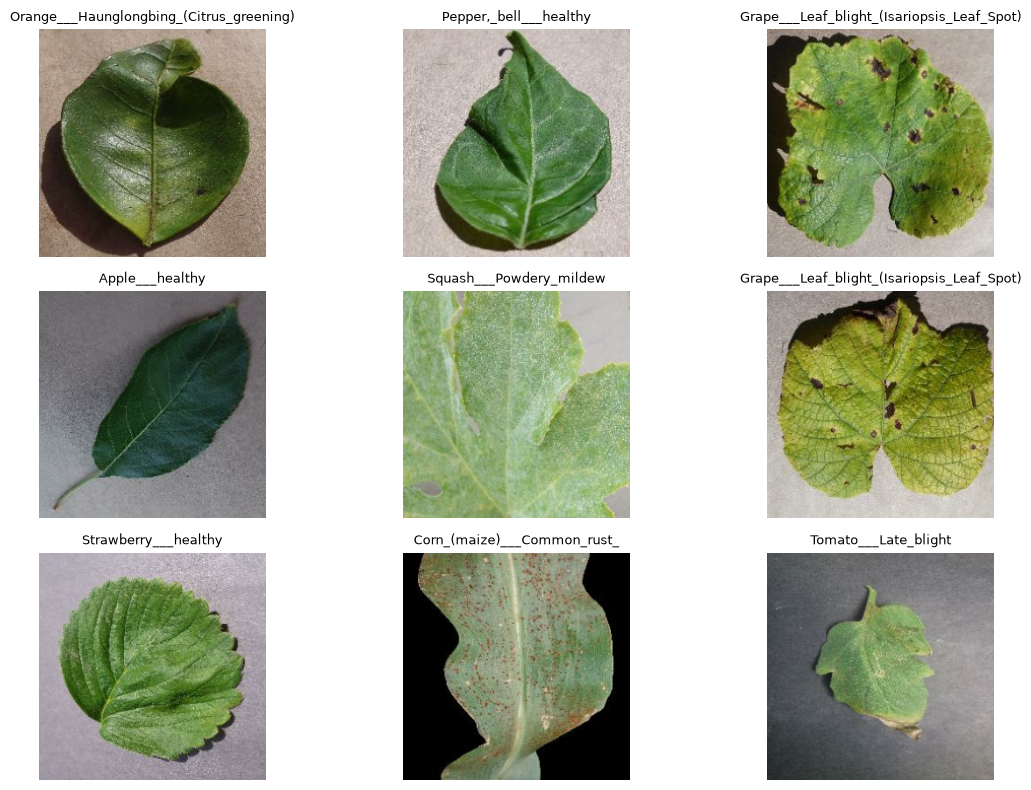

In [15]:
# ============================================================
# VISUALIZE PREPROCESSED IMAGES
# ============================================================

plt.figure(figsize=(12, 8))

for i in range(9):
    image = images[i].numpy()
    label = labels[i].numpy()

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[label], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

Data Augmentation

In [19]:
# ============================================================
# DATA AUGMENTATION
# ============================================================

data_augmentation = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
], name="data_augmentation")

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


Visualize Augmentation

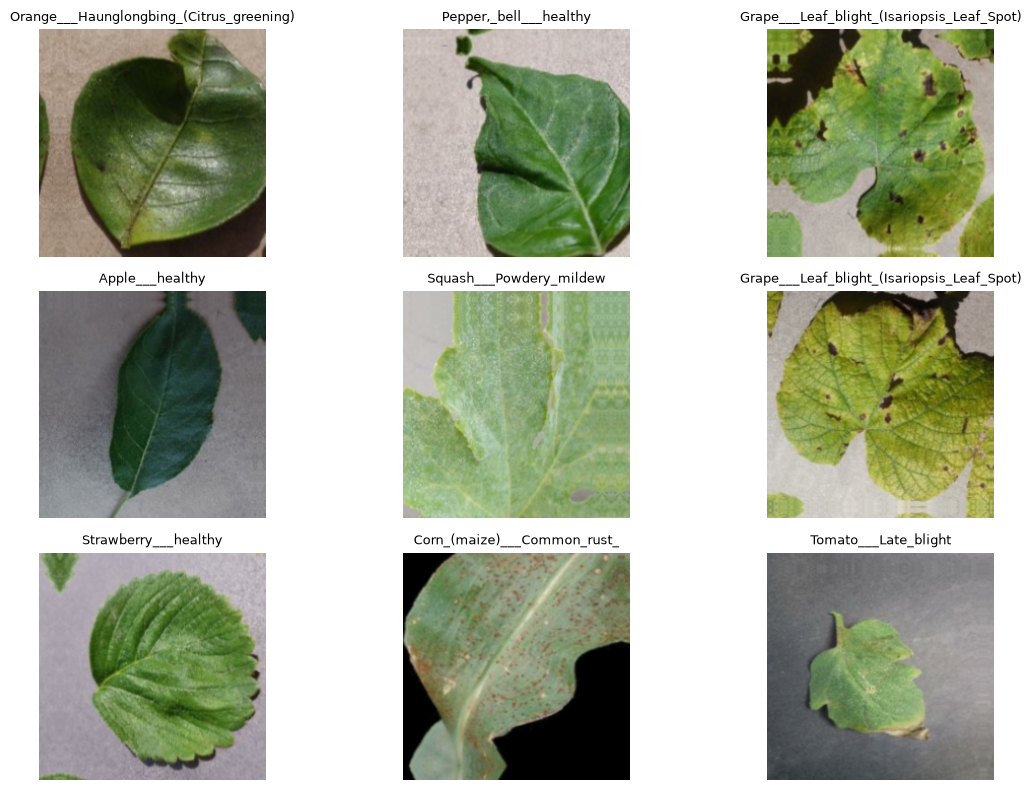

In [20]:
# ============================================================
# VISUALIZE AUGMENTED IMAGES
# ============================================================

# Take 9 images from the batch
sample_images = images[:9]

# Apply augmentation to the whole batch
augmented_images = data_augmentation(
    sample_images,
    training=True
)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(augmented_images[i].numpy())

    plt.title(
        class_names[labels[i].numpy()],
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Build the Baseline CNN

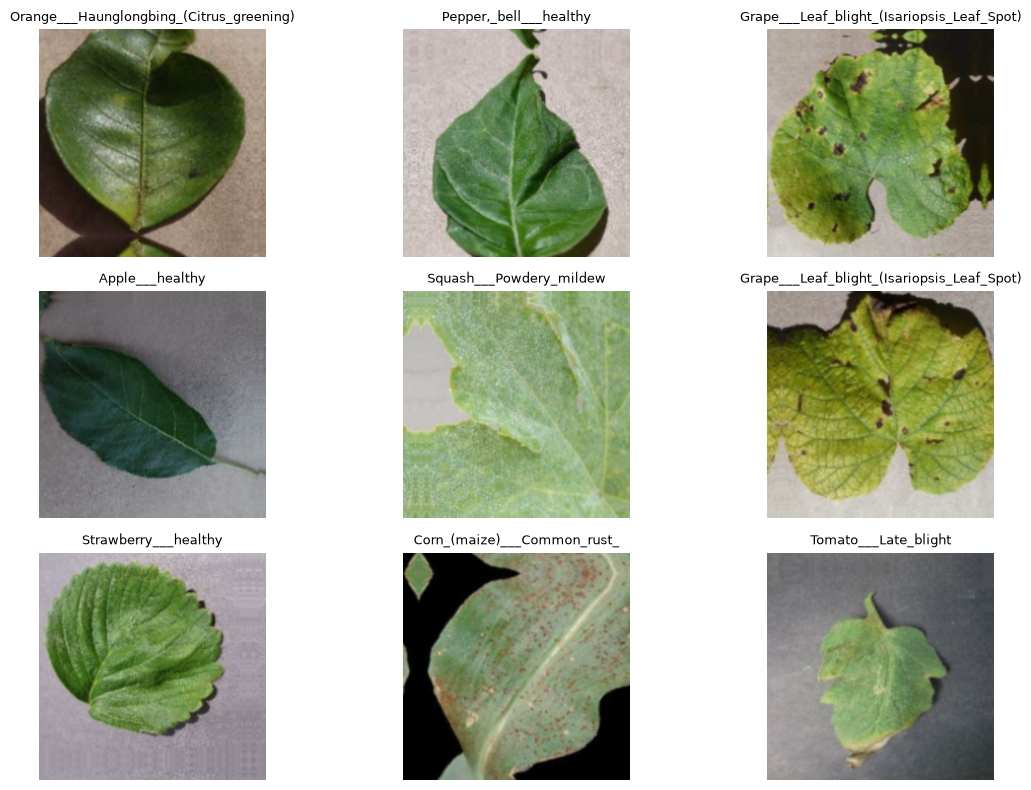

In [21]:
# ============================================================
# VISUALIZE AUGMENTED IMAGES
# ============================================================

# Take 9 images from the batch
sample_images = images[:9]

# Apply augmentation to the whole batch
augmented_images = data_augmentation(
    sample_images,
    training=True
)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    plt.imshow(augmented_images[i].numpy())

    plt.title(
        class_names[labels[i].numpy()],
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

 BASELINE CNN MODEL

In [22]:
# ============================================================
# BASELINE CNN MODEL
# ============================================================

baseline_cnn = keras.Sequential([
    
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation="softmax")

], name="baseline_cnn")

baseline_cnn.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,150 (383.40 KB)

 Trainable params: 98,150 (383.40 KB)

 Non-trainable params: 0 (0.00 B)

Compile the CNN

In [23]:
# ============================================================
# COMPILE BASELINE CNN
# ============================================================

baseline_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN compiled successfully!")

Baseline CNN compiled successfully!


Training Callbacks

In [24]:
# ============================================================
# TRAINING CALLBACKS
# ============================================================

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "baseline_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


Check your hardware

In [25]:
# Check available hardware

print("TensorFlow devices:")

for device in tf.config.list_physical_devices():
    print(device)

print("\nGPU devices:")
print(tf.config.list_physical_devices("GPU"))

print("\nCPU devices:")
print(tf.config.list_physical_devices("CPU"))

TensorFlow devices:
PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')

GPU devices:
[]

CPU devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


Small training test

In [26]:
# Small training test
# We use only a small portion of the training data
# to measure training speed and confirm the model learns.

history_test = baseline_cnn.fit(
    train_dataset.take(50),
    validation_data=val_dataset.take(10),
    epochs=1
)

c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 47s 898ms/step - accuracy: 0.1112 - loss: 3.4589 - val_accuracy: 0.1875 - val_loss: 3.3118


Train the Baseline CNN

In [27]:
# Train the baseline CNN

history_baseline = baseline_cnn.fit(
    train_dataset,
    validation_data=val_dataset, 
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 2654s 2s/step - accuracy: 0.3443 - loss: 2.3768 - val_accuracy: 0.5280 - val_loss: 1.6268
Epoch 2/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 2663s 2s/step - accuracy: 0.5362 - loss: 1.5872 - val_accuracy: 0.6541 - val_loss: 1.2339
Epoch 3/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1527s 1s/step - accuracy: 0.6290 - loss: 1.2461 - val_accuracy: 0.6235 - val_loss: 1.2876


Plot Training Performance

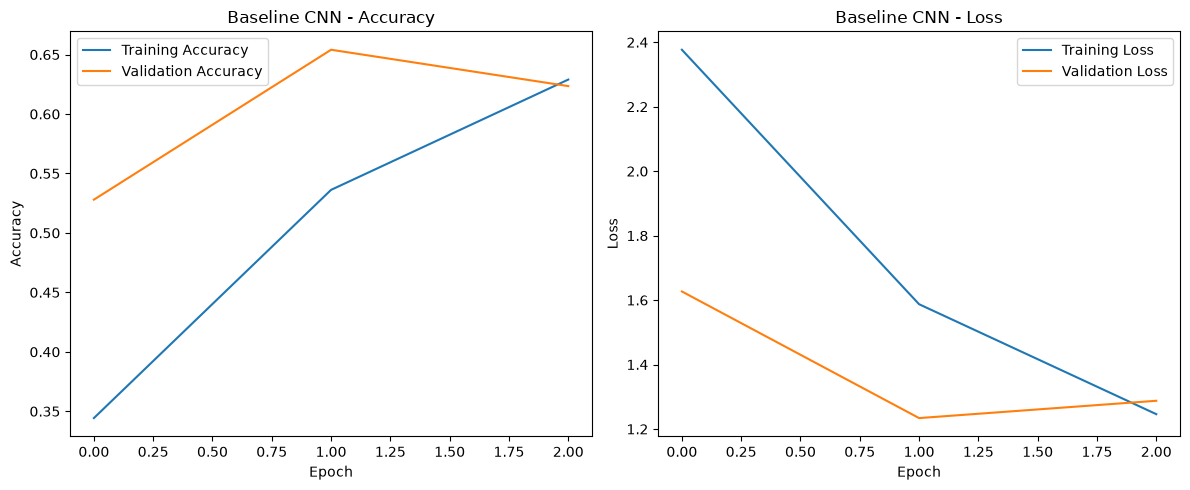

In [28]:
# Plot training and validation performance

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_baseline.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_baseline.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN - Accuracy")

plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_baseline.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_baseline.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN - Loss")

plt.legend()

plt.tight_layout()
plt.show()

Baseline Test Evaluation

In [29]:
# Evaluate the baseline CNN on the unseen test dataset

test_loss, test_accuracy = baseline_cnn.evaluate(
    test_dataset,
    verbose=1
)

print("\nBaseline CNN Test Results")
print("-------------------------")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

255/255 ━━━━━━━━━━━━━━━━━━━━ 53s 201ms/step - accuracy: 0.6604 - loss: 1.1993

Baseline CNN Test Results
-------------------------
Test Loss     : 1.1993
Test Accuracy : 0.6604
Test Accuracy : 66.04%


Load the Best Baseline Model

In [30]:
# Load the best checkpoint based on validation loss

best_baseline_cnn = keras.models.load_model(
    "baseline_cnn_best.keras"
)

print("Best baseline model loaded successfully!")

Best baseline model loaded successfully!


Evaluate Best Baseline

In [31]:
# Evaluate the best saved baseline model

best_test_loss, best_test_accuracy = best_baseline_cnn.evaluate(
    test_dataset,
    verbose=1
)

print("\nBest Baseline CNN Test Results")
print("------------------------------")
print(f"Test Loss     : {best_test_loss:.4f}")
print(f"Test Accuracy : {best_test_accuracy:.4f}")
print(f"Test Accuracy : {best_test_accuracy * 100:.2f}%")

255/255 ━━━━━━━━━━━━━━━━━━━━ 42s 159ms/step - accuracy: 0.6604 - loss: 1.1993

Best Baseline CNN Test Results
------------------------------
Test Loss     : 1.1993
Test Accuracy : 0.6604
Test Accuracy : 66.04%


Classification Report

In [32]:
# Generate predictions on the test dataset

y_true = []
y_pred = []

for images_batch, labels_batch in test_dataset:
    
    predictions = best_baseline_cnn.predict(
        images_batch,
        verbose=0
    )
    
    predicted_labels = np.argmax(
        predictions,
        axis=1
    )
    
    y_true.extend(labels_batch.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated successfully!")
print("Number of test samples:", len(y_true))

Predictions generated successfully!
Number of test samples: 8146


Generate the Classification Report

In [33]:
# Classification report for all 38 plant disease classes

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print("Baseline CNN Classification Report")
print("=" * 70)
print(report)

Baseline CNN Classification Report
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.53      0.32      0.40        94
                                 Apple___Black_rot       0.59      0.52      0.55        93
                          Apple___Cedar_apple_rust       0.00      0.00      0.00        41
                                   Apple___healthy       0.56      0.63      0.59       246
                               Blueberry___healthy       0.86      0.85      0.86       226
          Cherry_(including_sour)___Powdery_mildew       0.62      0.28      0.39       158
                 Cherry_(including_sour)___healthy       0.67      0.61      0.64       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.67      0.13      0.22        77
                       Corn_(maize)___Common_rust_       0.96      0.97      0.96       179
               Corn_(maize)___Northern_Leaf_

Confusion Matrix

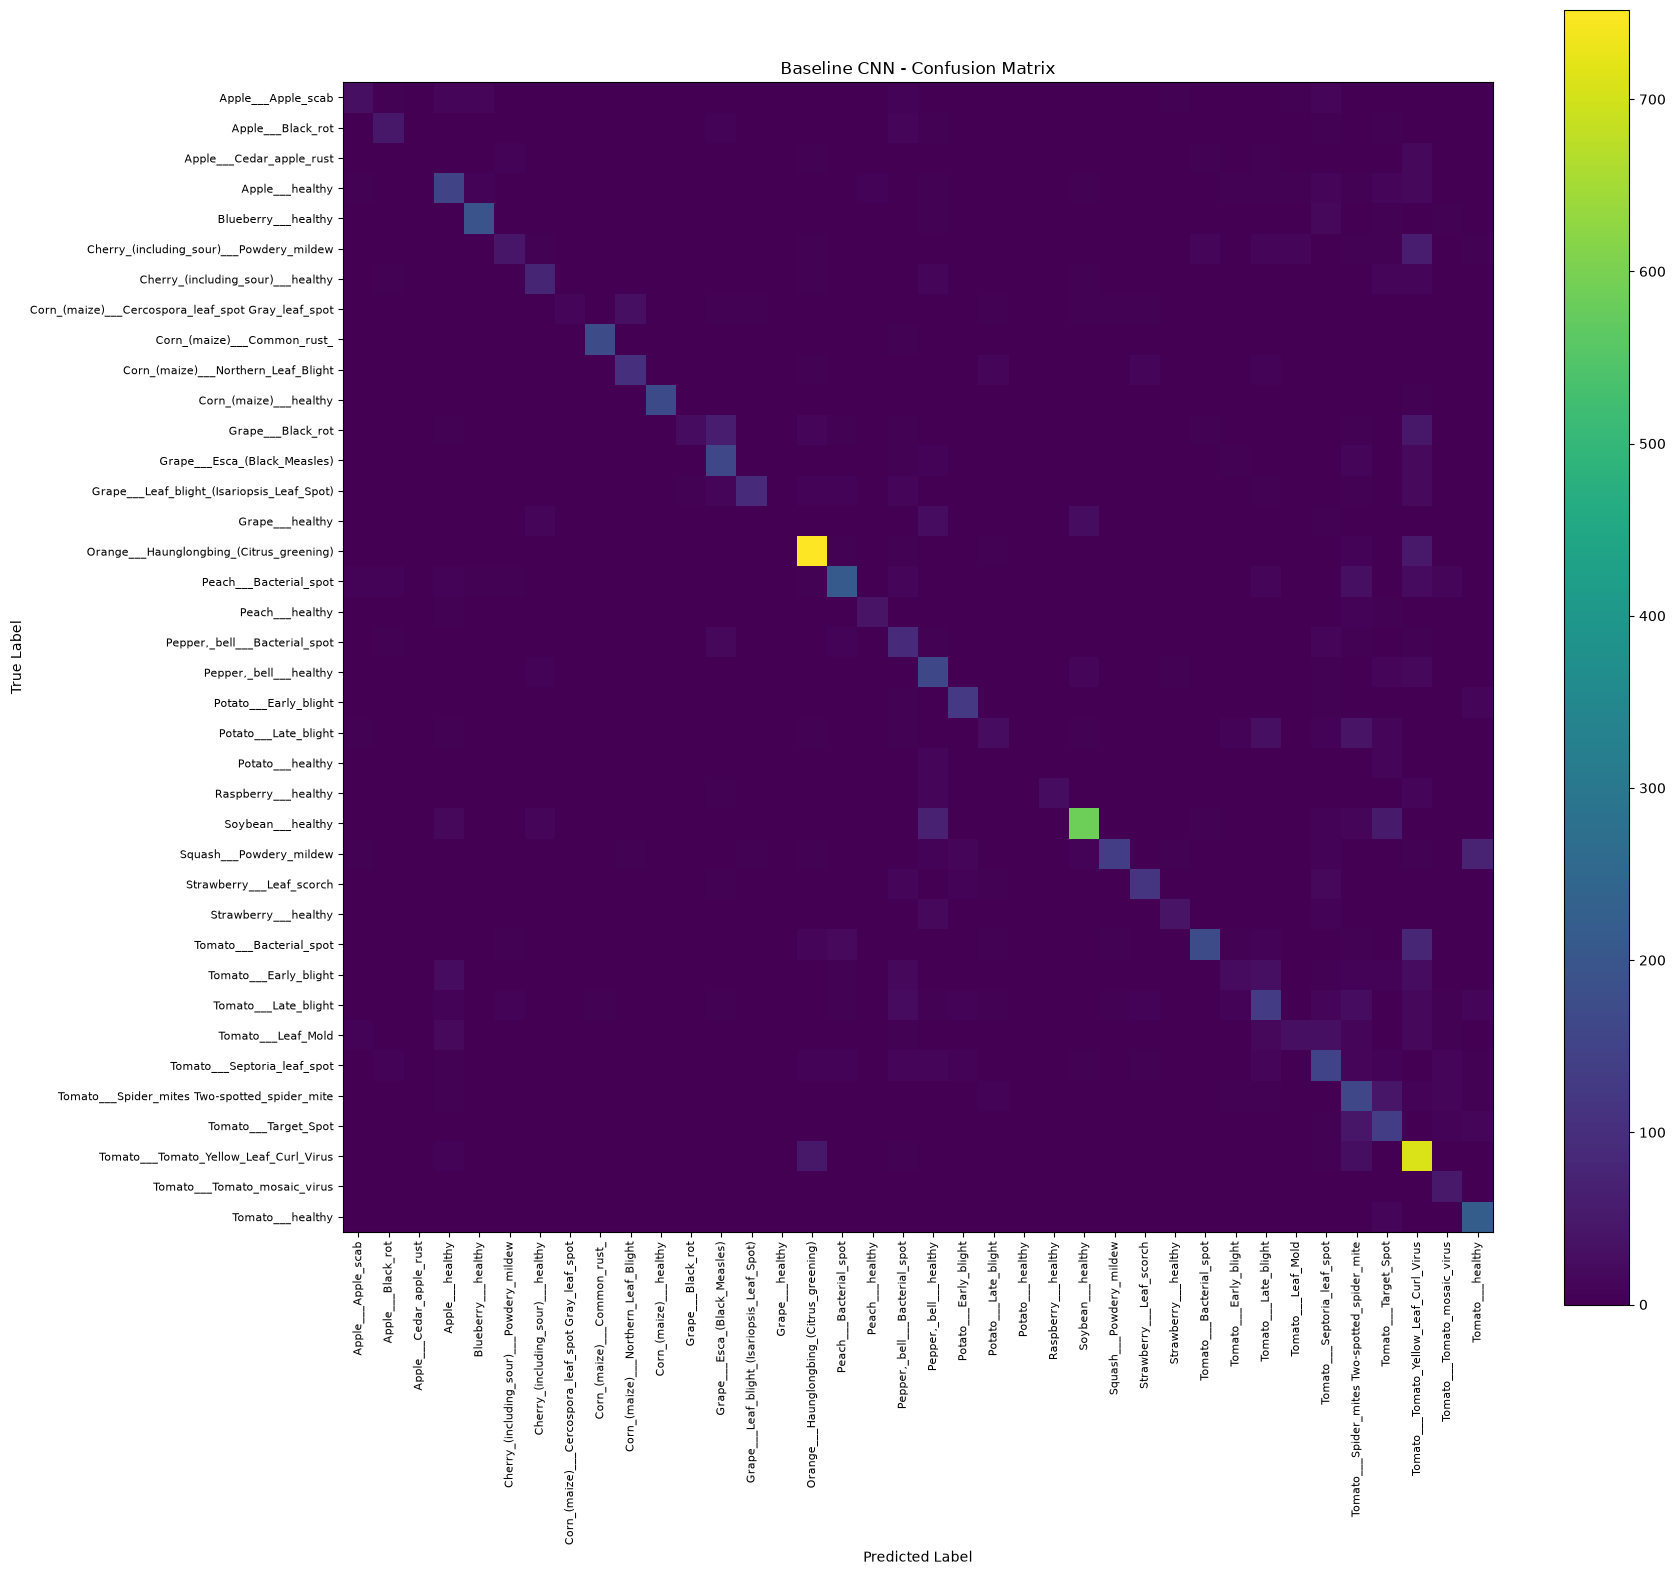

In [34]:
# Generate confusion matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(18, 16))

plt.imshow(cm, interpolation="nearest")
plt.title("Baseline CNN - Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(NUM_CLASSES),
    class_names,
    rotation=90,
    fontsize=8
)

plt.yticks(
    np.arange(NUM_CLASSES),
    class_names,
    fontsize=8
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

Create MobileNetV2 model

In [35]:
# ============================================================
# MobileNetV2 Transfer Learning Model
# ============================================================

base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

transfer_model = keras.Sequential([
    
    layers.Input(shape=(224, 224, 3)),
    
    # Our dataset is currently normalized to [0, 1].
    # MobileNetV2 expects inputs in [-1, 1].
    layers.Rescaling(
        scale=2.0,
        offset=-1.0
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )

], name="mobilenetv2_transfer")

transfer_model.summary()

Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile MobileNetV2

In [36]:
# Compile the MobileNetV2 transfer learning model

transfer_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 transfer model compiled successfully!")

MobileNetV2 transfer model compiled successfully!


Quick MobileNetV2 Training Test

In [37]:
# Quick MobileNetV2 training test

history_transfer_test = transfer_model.fit(
    train_dataset.take(50),
    validation_data=val_dataset.take(10),
    epochs=1
)

c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 46s 795ms/step - accuracy: 0.3694 - loss: 2.5374 - val_accuracy: 0.6469 - val_loss: 1.4666


Train MobileNetV2

In [38]:
# ============================================================
# Train MobileNetV2 Transfer Learning Model
# ============================================================

history_transfer = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=3,
    callbacks=callbacks
)

Epoch 1/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 920s 774ms/step - accuracy: 0.8788 - loss: 0.4234 - val_accuracy: 0.9395 - val_loss: 0.2044
Epoch 2/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1057s 890ms/step - accuracy: 0.9345 - loss: 0.2103 - val_accuracy: 0.9510 - val_loss: 0.1601
Epoch 3/3
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1311s 1s/step - accuracy: 0.9441 - loss: 0.1736 - val_accuracy: 0.9552 - val_loss: 0.1458


MobileNetV2 Test Evaluation

In [39]:
  # ============================================================
# Evaluate MobileNetV2 on the unseen test dataset
# ============================================================

transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(
    test_dataset,
    verbose=1
)

print("\nMobileNetV2 Test Results")
print("-----------------------")
print(f"Test Loss     : {transfer_test_loss:.4f}")
print(f"Test Accuracy : {transfer_test_accuracy:.4f}")
print(f"Test Accuracy : {transfer_test_accuracy * 100:.2f}%")

255/255 ━━━━━━━━━━━━━━━━━━━━ 175s 675ms/step - accuracy: 0.9540 - loss: 0.1526

MobileNetV2 Test Results
-----------------------
Test Loss     : 0.1526
Test Accuracy : 0.9540
Test Accuracy : 95.40%


MobileNetV2 Predictions

In [40]:
# ============================================================
# Generate MobileNetV2 predictions on the test dataset
# ============================================================

y_true_transfer = []
y_pred_transfer = []

for images_batch, labels_batch in test_dataset:

    predictions = transfer_model.predict(
        images_batch,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true_transfer.extend(labels_batch.numpy())
    y_pred_transfer.extend(predicted_labels)

y_true_transfer = np.array(y_true_transfer)
y_pred_transfer = np.array(y_pred_transfer)

print("MobileNetV2 predictions generated successfully!")
print("Number of test samples:", len(y_true_transfer))

MobileNetV2 predictions generated successfully!
Number of test samples: 8146


MobileNetV2 Classification Report

In [41]:
# ============================================================
# MobileNetV2 Classification Report
# ============================================================

transfer_report = classification_report(
    y_true_transfer,
    y_pred_transfer,
    target_names=class_names,
    zero_division=0
)

print("MobileNetV2 Classification Report")
print("=" * 70)
print(transfer_report)

MobileNetV2 Classification Report
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.90      0.94      0.92        94
                                 Apple___Black_rot       0.95      1.00      0.97        93
                          Apple___Cedar_apple_rust       0.95      1.00      0.98        41
                                   Apple___healthy       0.98      0.98      0.98       246
                               Blueberry___healthy       0.97      1.00      0.98       226
          Cherry_(including_sour)___Powdery_mildew       0.97      0.99      0.98       158
                 Cherry_(including_sour)___healthy       0.99      0.98      0.99       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.93      0.71      0.81        77
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       179
               Corn_(maize)___Northern_Leaf_B

MobileNetV2 confusion matrix

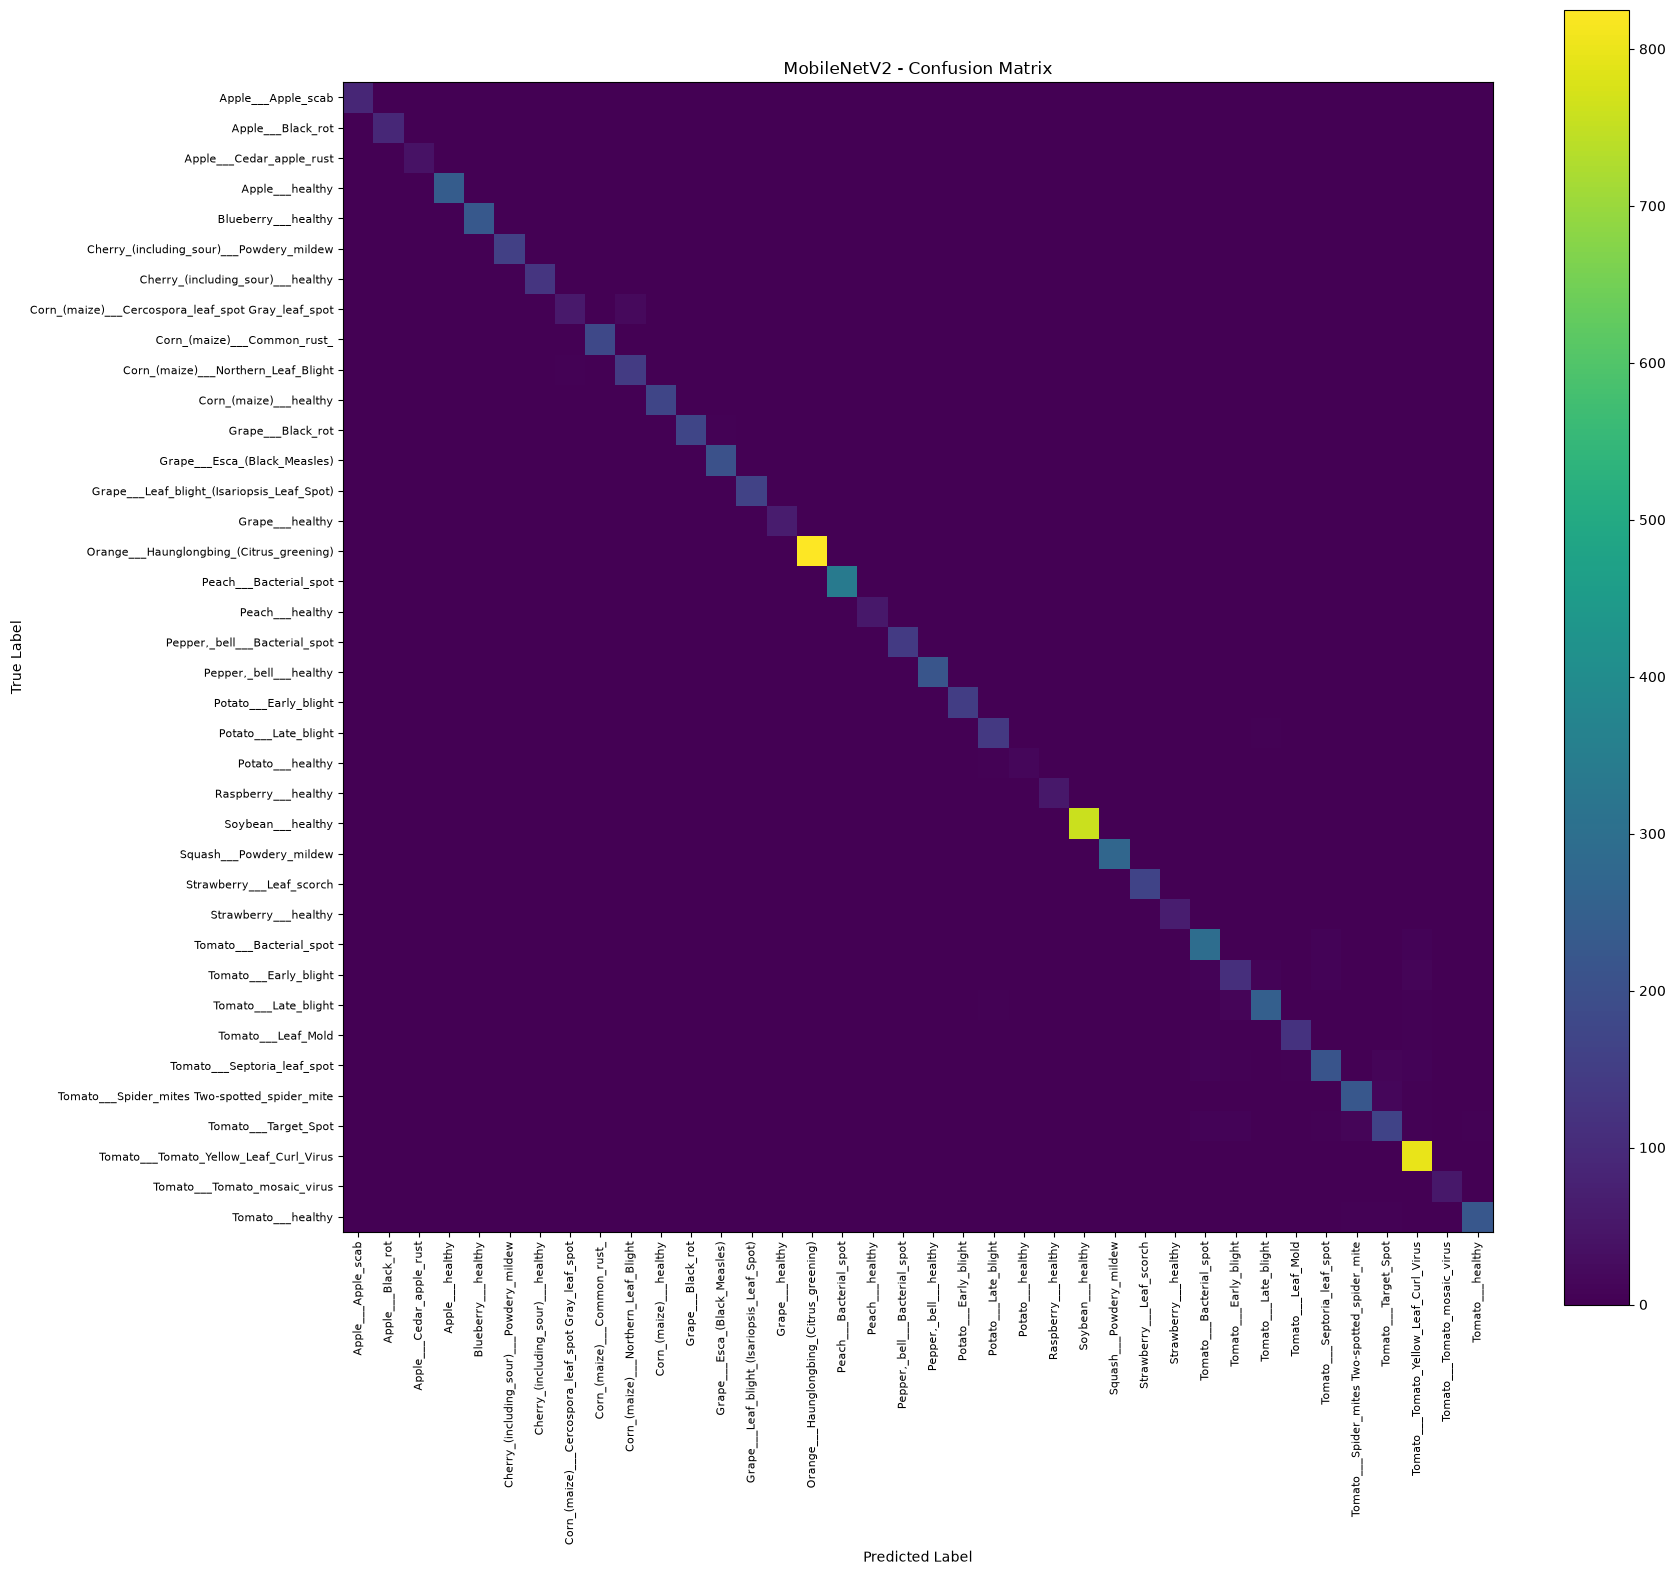

In [42]:
# ============================================================
# MobileNetV2 Confusion Matrix
# ============================================================

cm_transfer = confusion_matrix(
    y_true_transfer,
    y_pred_transfer
)

plt.figure(figsize=(18, 16))

plt.imshow(
    cm_transfer,
    interpolation="nearest"
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(NUM_CLASSES),
    class_names,
    rotation=90,
    fontsize=8
)

plt.yticks(
    np.arange(NUM_CLASSES),
    class_names,
    fontsize=8
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

Save Final Model

In [43]:
# ============================================================
# Save Final MobileNetV2 Model
# ============================================================

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_PATH = MODEL_DIR / "plant_disease_mobilenetv2.keras"

transfer_model.save(FINAL_MODEL_PATH)

print("Final model saved successfully!")
print("Model path:")
print(FINAL_MODEL_PATH)

Final model saved successfully!
Model path:
c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\models\plant_disease_mobilenetv2.keras


Save the 38 class names

In [44]:
# ============================================================
# Save Class Names
# ============================================================

import json

CLASS_NAMES_PATH = MODEL_DIR / "class_names.json"

with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(
        class_names,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Class names saved successfully!")
print("Path:")
print(CLASS_NAMES_PATH)

print("\nNumber of classes:", len(class_names))

Class names saved successfully!
Path:
c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\models\class_names.json

Number of classes: 38


Save model metadata

In [45]:
# ============================================================
# Save Model Metadata
# ============================================================

metadata = {
    "model_name": "MobileNetV2",
    "input_size": [224, 224],
    "num_classes": NUM_CLASSES,
    "normalization": "pixel_values / 255.0",
    "mobilenetv2_scaling": "[-1, 1] using Rescaling(scale=2.0, offset=-1.0)",
    "test_accuracy": float(transfer_test_accuracy),
    "macro_f1": 0.94
}

METADATA_PATH = MODEL_DIR / "metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

print("Model metadata saved successfully!")
print("Path:")
print(METADATA_PATH)

print("\nMetadata:")
print(json.dumps(metadata, indent=2))

Model metadata saved successfully!
Path:
c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\models\metadata.json

Metadata:
{
  "model_name": "MobileNetV2",
  "input_size": [
    224,
    224
  ],
  "num_classes": 38,
  "normalization": "pixel_values / 255.0",
  "mobilenetv2_scaling": "[-1, 1] using Rescaling(scale=2.0, offset=-1.0)",
  "test_accuracy": 0.9539651274681091,
  "macro_f1": 0.94
}


Test the saved model with one real leaf image

In [46]:
# ============================================================
# Single Image Prediction Test
# ============================================================

def predict_plant_disease(image_path):
    """
    Predict plant disease from a single leaf image.
    """

    # Load image
    image = tf.io.read_file(str(image_path))

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Resize to model input size
    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    # Normalize exactly as during training
    image = tf.cast(image, tf.float32) / 255.0

    # Add batch dimension
    image = tf.expand_dims(image, axis=0)

    # Prediction
    predictions = transfer_model.predict(
        image,
        verbose=0
    )

    predicted_index = np.argmax(predictions[0])
    confidence = predictions[0][predicted_index]

    predicted_class = class_names[predicted_index]

    return predicted_class, float(confidence)


# Pick one image from the test dataset
sample_image_path = test_df.iloc[0]["image_path"]

predicted_class, confidence = predict_plant_disease(
    sample_image_path
)

actual_class = test_df.iloc[0]["class_name"]

print("Image:", sample_image_path)
print("\nActual class    :", actual_class)
print("Predicted class :", predicted_class)
print("Confidence      :", f"{confidence * 100:.2f}%")

Image: c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\data\raw\plantvillage dataset\color\Tomato___Late_blight\747a2385-2777-445a-b215-7a14a5c0135c___RS_Late.B 7111.JPG

Actual class    : Tomato___Late_blight
Predicted class : Tomato___Late_blight
Confidence      : 98.07%


Visual prediction

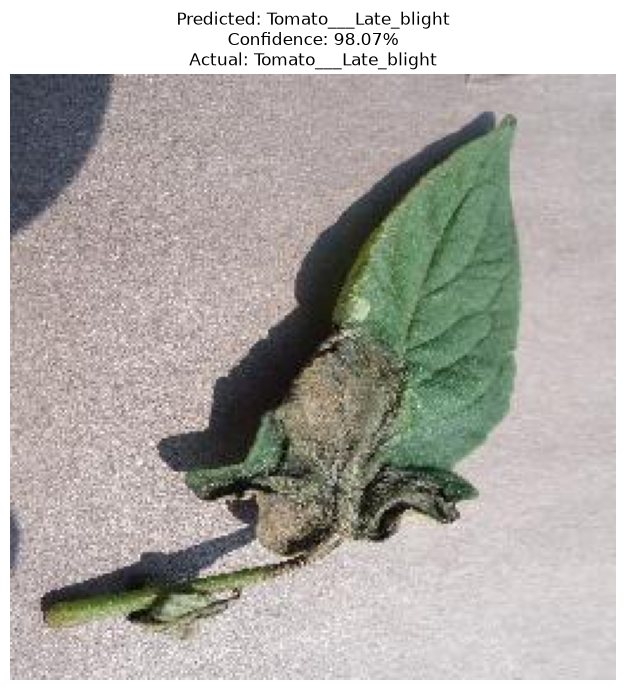

In [47]:
# ============================================================
# Visualize Single Image Prediction
# ============================================================

image = Image.open(sample_image_path)

plt.figure(figsize=(7, 7))

plt.imshow(image)
plt.axis("off")

plt.title(
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%\n"
    f"Actual: {actual_class}",
    fontsize=12
)

plt.tight_layout()
plt.show()

Model Comparison

In [48]:
# ============================================================
# Model Comparison
# ============================================================

model_comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "MobileNetV2 Transfer Learning"
    ],
    "Test Accuracy": [
        test_accuracy,
        transfer_test_accuracy
    ],
    "Macro F1": [
        0.55,
        0.94
    ],
    "Weighted F1": [
        0.65,
        0.95
    ]
})

model_comparison

,Model,Test Accuracy,Macro F1,Weighted F1
0,Baseline CNN,0.660447,0.55,0.65
1,MobileNetV2 Transfer Learning,0.953965,0.94,0.95


In [49]:
# Display accuracy as percentages

comparison_display = model_comparison.copy()

comparison_display["Test Accuracy"] = (
    comparison_display["Test Accuracy"] * 100
).round(2)

comparison_display["Macro F1"] = (
    comparison_display["Macro F1"] * 100
).round(2)

comparison_display["Weighted F1"] = (
    comparison_display["Weighted F1"] * 100
).round(2)

comparison_display

,Model,Test Accuracy,Macro F1,Weighted F1
0,Baseline CNN,66.04,55.0,65.0
1,MobileNetV2 Transfer Learning,95.40,94.0,95.0


Verify saved model files

In [50]:
# ============================================================
# Verify Saved Model Files
# ============================================================

print("MODEL FILES")
print("=" * 50)

for file in MODEL_DIR.iterdir():
    if file.is_file():
        size_mb = file.stat().st_size / (1024 * 1024)
        print(f"{file.name:<40} {size_mb:.2f} MB")

MODEL FILES
class_names.json                         0.00 MB
metadata.json                            0.00 MB
plant_disease_mobilenetv2.keras          9.74 MB


Create the API folder

In [51]:
# ============================================================
# Create Production Folders
# ============================================================

API_DIR = PROJECT_ROOT / "api"
APP_DIR = PROJECT_ROOT / "app"

API_DIR.mkdir(parents=True, exist_ok=True)
APP_DIR.mkdir(parents=True, exist_ok=True)

print("Production folders created successfully!")

print("\nAPI folder :", API_DIR)
print("App folder :", APP_DIR)

Production folders created successfully!

API folder : c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\api
App folder : c:\Users\deept\OneDrive\Desktop\Plant_Disease Prediction Project\app
